# PCA and Kalman statistical arbitrage

Reproduce the frozen residual-reversal experiment, then compare fixed versus calibrated Kalman exposures and equal versus inverse-volatility sizing. The implementation is independent; data snapshots and numerical reference outputs are fixed to preserve the archived calculation.

The first cell recomputes all results and fails if any of the 80 reference rows differs by more than 1e-9 across eight measures. Reference reproduction does not establish a tradable edge.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display, Image
from equity_stat_arb.pipeline import run
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/equity_stat_arb").exists())
manifest = run(ROOT, verify=True)
metrics = pd.read_csv(ROOT / "artifacts/metrics.csv")
daily = pd.read_parquet(ROOT / "artifacts/daily_returns.parquet")
calibration = pd.read_csv(ROOT / "artifacts/calibration.csv")
verification = pd.read_csv(ROOT / "artifacts/verification.csv")
print("Maximum absolute verification error:", verification.filter(like="absolute_error").max().max())

Evaluating technology


Evaluating financial


Evaluating energy


Evaluating uk_external


Reference verified: 80 rows, 8 measures per row.


   universe                         variant   sharpe     cagr  max_drawdown
 technology                     PCA / equal 0.447512 0.048342     -0.179287
 technology            Fixed Kalman / equal 0.457638 0.049799     -0.188005
 technology       Calibrated Kalman / equal 0.936708 0.109590     -0.131433
 technology      Fixed Kalman / inverse vol 0.577896 0.061350     -0.195913
 technology Calibrated Kalman / inverse vol 1.116166 0.125115     -0.126848
  financial                     PCA / equal 0.463981 0.032334     -0.112286
  financial            Fixed Kalman / equal 0.625975 0.046216     -0.110578
  financial       Calibrated Kalman / equal 0.482072 0.036938     -0.125304
  financial      Fixed Kalman / inverse vol 0.616675 0.045985     -0.128052
  financial Calibrated Kalman / inverse vol 0.458030 0.035017     -0.141781
     energy                     PCA / equal 0.231031 0.021183     -0.162295
     energy            Fixed Kalman / equal 0.231031 0.021183     -0.162295
     energy 

Maximum absolute verification error: 7.771561172376096e-16


## Data

Four separate return panels of 15 stocks each. Technology spans 2022–2026; financials, energy and UK equities span 2017–2021. Results are compared within each panel. The universes are hand-picked, so survivorship and universe-selection bias remain.

The frozen CSV inputs are downloaded from [the pinned dataset snapshot](https://github.com/b-enh/pca-stat-arb/tree/6a24304205318de080b019e74ac766e7cdb18ff6). Their exact source URLs and SHA-256 hashes are retained below. Changing the inputs would define a different experiment.

In [2]:
display(pd.DataFrame(manifest["data"])[["universe", "stocks", "observations", "start", "end", "source_url"]])
print("Reference checked:", manifest["reference_verified"])

,universe,stocks,observations,start,end,source_url
0,technology,15,1003,2022-08-09,2026-08-07,https://raw.githubusercontent.com/b-enh/pca-st...
1,financial,15,1258,2017-01-04,2021-12-31,https://raw.githubusercontent.com/b-enh/pca-st...
2,energy,15,1258,2017-01-04,2021-12-31,https://raw.githubusercontent.com/b-enh/pca-st...
3,uk_external,15,1264,2017-01-04,2021-12-31,https://raw.githubusercontent.com/b-enh/pca-st...


Reference checked: True


## Models

Correlation PCA is estimated by eigendecomposition of the standardized-return covariance matrix. A 126-day trailing window refits every 10 days and retains the factor count needed for 55% explained variance.

$$r^{std}_{i,t}=\alpha_{i,t}+\beta_{i,t}^{\top}f_t+\epsilon_{i,t}.$$

The PCA variant projects out these factors. Kalman variants adapt intercepts and loadings, saving the innovation before each state update. Filters reset when the PCA basis changes. The fixed process-noise scale is `1e-4`.

## Calibration

The first 84 observations of each past window fit PCA, scaling and observation noise. The remaining 42 observations score sequential Gaussian predictive likelihood for `Q = 0, 1e-4, 1e-2`. Observation-noise scale remains fixed at 1. The best of those three candidates is used for the next production block, fitted on all 126 past observations. No portfolio return is used as the calibration objective.

## Signals and allocation

The signal is negative five-day residual pressure divided by 20-day residual volatility. After 252 residual observations of initial history, the ranking selects three longs and three shorts every 20 days. Equal sizing allocates 50% per side. Risk sizing uses raw stock volatility from the preceding 20 days, with a 25% target weight cap.

Targets are carried forward and lagged one day before earning returns. For exact reproduction, weights are treated as constant between scheduled signal rebalances. Costs count only changes in those targets. This omits holding drift and trades needed to maintain constant weights; it is not a self-financing execution simulation.

## Results

All variants use the same dates and costs within each universe. The archived initial flat period is included in headline Sharpe/CAGR; `trading_sample_sharpe` excludes it. There is no newly untouched holdout in these already inspected histories.

variant,Calibrated Kalman / equal,Calibrated Kalman / inverse vol,Fixed Kalman / equal,Fixed Kalman / inverse vol,PCA / equal
universe,,,,,
energy,0.388,0.367,0.231,0.206,0.231
financial,0.482,0.458,0.626,0.617,0.464
technology,0.937,1.116,0.458,0.578,0.448
uk_external,0.656,0.617,0.707,0.662,0.707


,universe,variant,days,cagr,max_drawdown,average_daily_turnover,max_weight,trading_sample_sharpe
2,technology,PCA / equal,877,0.0483,-0.1793,0.0593,0.1667,0.5305
6,technology,Fixed Kalman / equal,877,0.0498,-0.1880,0.0601,0.1667,0.5425
10,technology,Calibrated Kalman / equal,877,0.1096,-0.1314,0.0601,0.1667,1.1110
14,technology,Fixed Kalman / inverse vol,877,0.0613,-0.1959,0.0612,0.2500,0.6851
18,technology,Calibrated Kalman / inverse vol,877,0.1251,-0.1268,0.0611,0.2500,1.3243
22,financial,PCA / equal,1132,0.0323,-0.1123,0.0654,0.1667,0.5265
26,financial,Fixed Kalman / equal,1132,0.0462,-0.1106,0.0654,0.1667,0.7104
30,financial,Calibrated Kalman / equal,1132,0.0369,-0.1253,0.0654,0.1667,0.5471
34,financial,Fixed Kalman / inverse vol,1132,0.0460,-0.1281,0.0661,0.2500,0.6999
38,financial,Calibrated Kalman / inverse vol,1132,0.0350,-0.1418,0.0661,0.2500,0.5198


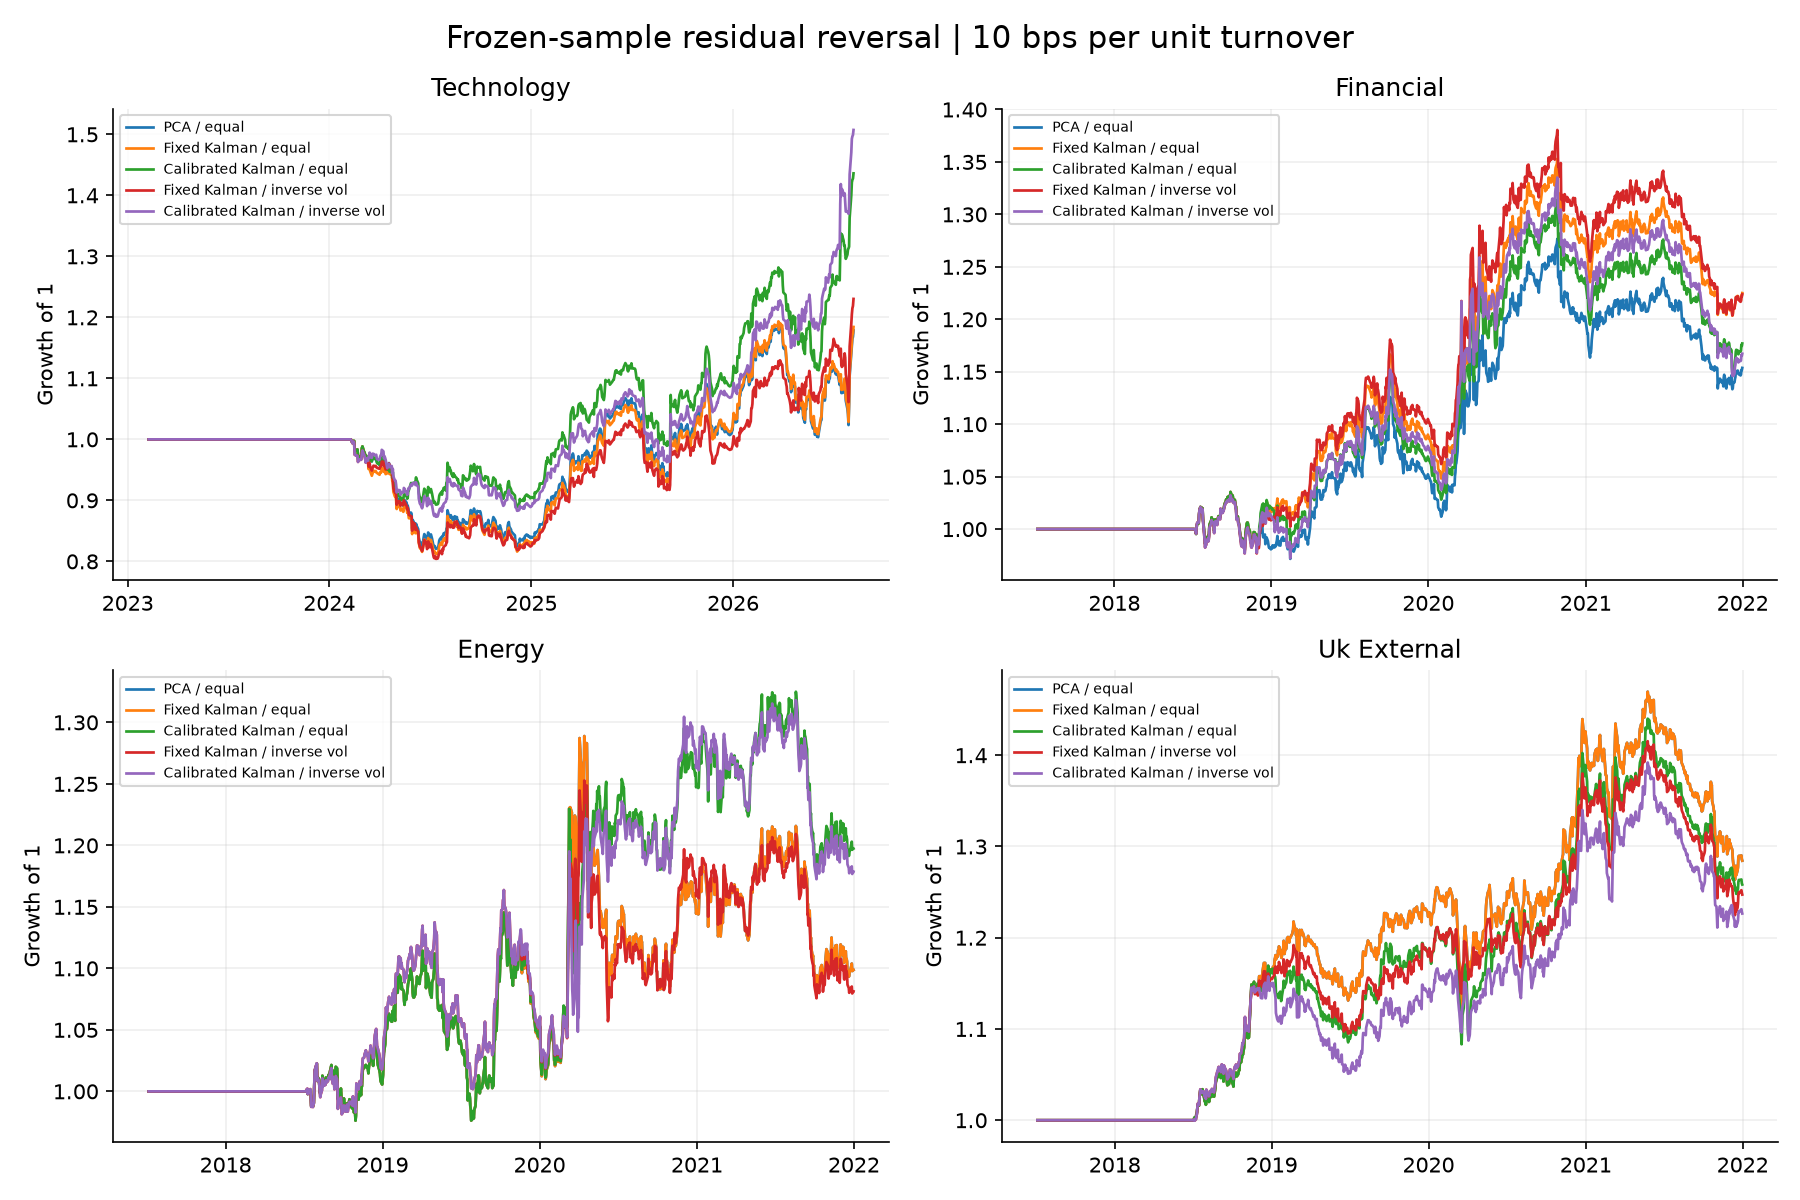

In [3]:
at_10 = metrics[metrics.cost_bps == 10]
display(at_10.pivot(index="universe", columns="variant", values="sharpe").round(3))
display(at_10[["universe", "variant", "days", "cagr", "max_drawdown", "average_daily_turnover", "max_weight", "trading_sample_sharpe"]].round(4))
display(Image(filename=str(ROOT / "artifacts/overview.png")))

## Cost sensitivity and calibration choices

The cost rate is per unit of absolute target-weight turnover. An opening and closing trade each incur a charge. Actual maintenance trades, borrow fees, financing and market impact are not included.

In [4]:
for universe in ["technology", "financial", "energy", "uk_external"]:
    print(universe.upper())
    subset = metrics[metrics.universe == universe]
    display(subset.pivot(index="cost_bps", columns="variant", values="sharpe").round(3))
print("Noise choices across refits:")
display(calibration.groupby(["universe", "q"]).size().unstack(fill_value=0))
print("Numerical reference comparison:")
display(verification.groupby("universe").max(numeric_only=True).filter(like="absolute_error"))

TECHNOLOGY


variant,Calibrated Kalman / equal,Calibrated Kalman / inverse vol,Fixed Kalman / equal,Fixed Kalman / inverse vol,PCA / equal
cost_bps,,,,,
0,1.065,1.256,0.582,0.714,0.570
5,1.001,1.186,0.520,0.646,0.509
10,0.937,1.116,0.458,0.578,0.448
20,0.807,0.975,0.333,0.441,0.324


FINANCIAL


variant,Calibrated Kalman / equal,Calibrated Kalman / inverse vol,Fixed Kalman / equal,Fixed Kalman / inverse vol,PCA / equal
cost_bps,,,,,
0,0.682,0.660,0.838,0.829,0.684
5,0.582,0.559,0.733,0.723,0.575
10,0.482,0.458,0.626,0.617,0.464
20,0.281,0.255,0.411,0.402,0.242


ENERGY


variant,Calibrated Kalman / equal,Calibrated Kalman / inverse vol,Fixed Kalman / equal,Fixed Kalman / inverse vol,PCA / equal
cost_bps,,,,,
0,0.519,0.504,0.362,0.345,0.362
5,0.453,0.435,0.296,0.276,0.296
10,0.388,0.367,0.231,0.206,0.231
20,0.257,0.229,0.100,0.067,0.100


... (2 outputs left out)

Noise choices across refits:


q,0.0000,0.0001,0.0100
universe,,,
energy,19,79,16
financial,13,74,27
technology,8,35,45
uk_external,8,61,45


Numerical reference comparison:


,days_absolute_error,sharpe_absolute_error,cagr_absolute_error,max_drawdown_absolute_error,trading_sample_sharpe_absolute_error,average_daily_turnover_absolute_error,max_weight_absolute_error,max_absolute_net_exposure_absolute_error
universe,,,,,,,,
energy,0,3.885781e-16,2.220446e-16,3.330669e-16,3.330669e-16,0.0,0.0,0.000000e+00
financial,0,2.775558e-16,2.220446e-16,7.771561e-16,3.330669e-16,0.0,0.0,2.775558e-17
technology,0,4.440892e-16,2.220446e-16,1.110223e-16,4.440892e-16,0.0,0.0,1.387779e-17
uk_external,0,3.330669e-16,2.220446e-16,4.440892e-16,4.440892e-16,0.0,0.0,2.775558e-17


## Notes

The combined variant improves technology and energy in this frozen sample but weakens financials and UK equities. Its technology Sharpe is about 1.116 at 10 bps, with maximum drawdown of about 12.68%. This is an individual historical result under the stated approximation, not an overall portfolio Sharpe or a live-performance claim.

The main limitations are previously inspected histories, different panel periods, small hand-picked universes, initial flat-day padding and simplified turnover accounting. Dollar neutrality is not factor neutrality. There is no Robust PCA, C++, or stationarity/FDR screening in this implementation.

Tests cover causal models and calibration, zero-noise PCA recovery, capped sizing, target-weight lag and costs, input checksums and reference verification. Run `python -m equity_stat_arb.pipeline --verify` to rebuild and verify, and `python -m pytest -q` for the offline checks.